# Phase 4: memory policies and Relay-BP

Executable research walkthrough. Production calibration, fresh evaluation, factorial evidence, and their full analysis remain pending. Fixture mode verifies notebook plumbing only; every fixture is `development_fixture` / `not_assessed`. No decoder performance or circuit-reproduction conclusion is drawn from it.

In [1]:
import os, sys
from pathlib import Path
root = Path(os.environ["PHASE4_REPOSITORY_ROOT"]).resolve()
sys.path.insert(0, str(root / "scripts"))
from phase4_notebook_support import notebook_inventory, ANALYSIS_VERSIONS, validate_environment
from execute_phase4_notebook import project_interpreter
project_interpreter(root)
validate_environment()
fixture = os.environ.get("PHASE4_NOTEBOOK_FIXTURE") == "1"
stages = notebook_inventory(root, fixture=fixture)
print("Mode:", "development_fixture" if fixture else "qualified_snapshot_inventory")
print("Assessment: not_assessed; no production sampling in this notebook")
from phase4_notebook_campaign import build_campaign_snapshots
from phase4_notebook_presentation import display_campaign_stage, presentation_views, equation_check_table
from execute_phase4_notebook import campaign_input_root
campaign_root = campaign_input_root(root, Path(os.environ.get("PHASE4_CAMPAIGN_ROOT", str(root))))
campaign = presentation_views(build_campaign_snapshots(root, campaign_root=campaign_root, development_fixture=fixture))
campaign["tables"].append(equation_check_table())
campaign["artifacts"]["equations"] = {"status": "deterministic_checks_passed", "execution_qualified": False, "kind": "deterministic_equation_fixture", "reason": "Five source-linked primitive examples passed; no physical samples drawn."}
figure_dir = Path(os.environ["PHASE4_NOTEBOOK_FIGURE_ROOT"])
print("Read-only campaign input:", campaign_root)
print("Qualified originating stages:", campaign["summary"]["qualified_stages"])


Mode: development_fixture
Assessment: not_assessed; no production sampling in this notebook


Read-only campaign input: /hpc/group/pfisterlab/mg551/storage/survey_bp_memory_integration_20260926
Qualified originating stages: []


## 1. Identity and environment

Exact reuse binds manifest, source/policy, ordered code identity, environment, physical samples, stage, caps and selected settings. Pinning current analysis versions does not retroactively qualify old execution. See the originating ledgers and `data/evidence/relay-v0.2.2-source.json`.

In [2]:
record = campaign.get('artifacts', {}).get('identity', stages['identity'])
print("Pinned analysis versions:", ANALYSIS_VERSIONS)
view = display_campaign_stage('identity', record, campaign, figure_dir=figure_dir)


Pinned analysis versions: {'numpy': '2.2.6', 'matplotlib': '3.10.9', 'nbformat': '5.10.4', 'nbclient': '0.10.2', 'ipykernel': '6.29.5'}


## 2. Deterministic equations and history

Source equations and CSS adaptations are recorded in `docs/memory-policy-sources.md`. V2C damping weights fresh V2C; PDBP mixes fields; PD-prime mixes C2V deltas; momentum keeps private velocity; EWA and uniform Relay affine memory agree under gamma = 1 - alpha. History commits require an admitted complete sweep. The supplement records executable prior -> fields -> V2C operand order.

In [3]:
print("Deterministic primitive checks: five passed; no campaign shots consumed")
record = campaign.get('artifacts', {}).get('equations', stages['equations'])
view = display_campaign_stage('equations', record, campaign, figure_dir=figure_dir)


Deterministic primitive checks: five passed; no campaign shots consumed


primitive,equation,parameters,observed,expected,check
affine prior,(1-alpha) base + alpha previous,{'alpha': 0.25},"[2.5, -0.5]","[2.5, -0.5]",passed
V2C damping,(1-gamma) old + gamma fresh,{'gamma': 0.25},"[2.5, 1.5]","[2.5, 1.5]",passed
PDBP,(1-gamma) fresh + gamma old,{'gamma': 0.25},"[-0.5, 2.5]","[-0.5, 2.5]",passed
PD-prime,old + (1-gamma) sum(fresh C2V - old C2V),{'gamma': 0.25},"[4.75, 1.75]","[4.75, 1.75]",passed
posterior momentum,g = gamma g_old + (1-gamma)(Q_old - fresh); Q = Q_old - alpha g,"{'alpha': 0.5, 'gamma': 0.25, 'old_velocity': [0.0, 0.0]}","[1.75, 1.75]","[1.75, 1.75]",passed


## 3. Baseline scan

Compare baseline controls on the prespecified code/noise grid. Retain failures and all-shot denominators. Generated HGP remains non-paper-exact; B1 identity comes from the retained resolution record.

stage,code_id,arm,error_rate,failures,denominator,estimate,wilson_95,runtime_tails,runtime_scope,resource_tails,diagnostic_cells,selected_valid_syndrome_logical_error,termination_counts,work_vectors
baseline,development-fixture-code,fixture-baseline,0.03,1,7,0.142857,"[0.02567962434474355, 0.5131278292743189]",{'p95': 0.01},synthetic development fixture,{'missing': 1},unavailable,unavailable,unavailable,unavailable


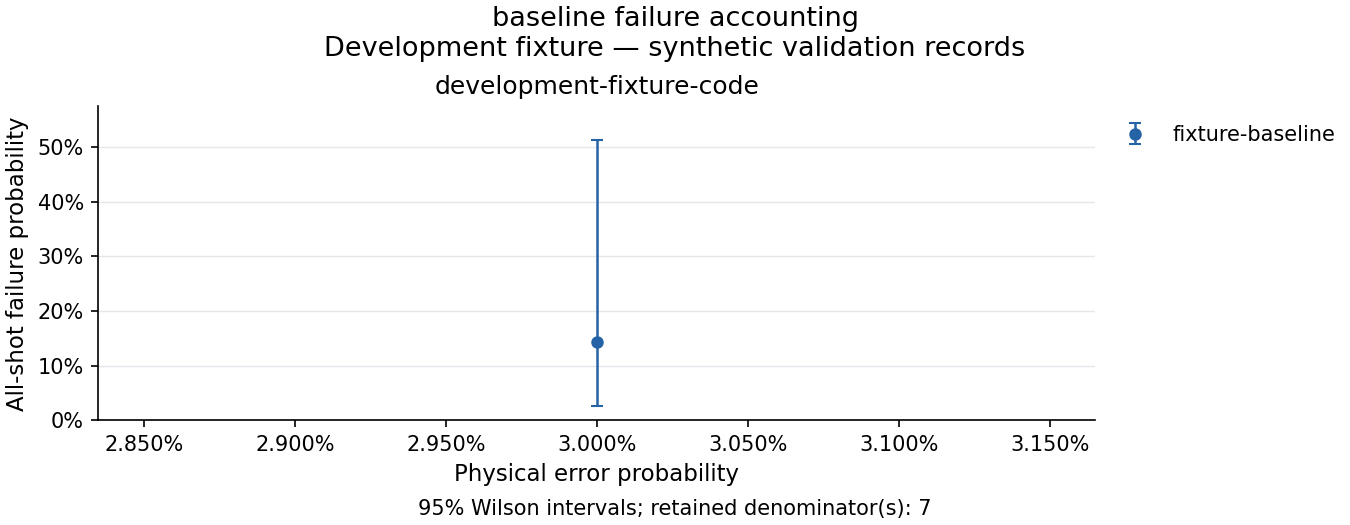

In [4]:
record = campaign.get('artifacts', {}).get('baseline', stages['baseline'])
view = display_campaign_stage('baseline', record, campaign, figure_dir=figure_dir)


## 4. Compute benchmark and frozen caps

Use the active-V4 timing report and its frozen cap manifest. Directional work, controller work, elapsed time, and resources retain separate units. A native iteration count is not canonical C2V work.

stage,code_id,arm,error_rate,failures,denominator,estimate,wilson_95,runtime_tails,runtime_scope,resource_tails,diagnostic_cells,selected_valid_syndrome_logical_error,termination_counts,work_vectors
benchmark,development-fixture-code,fixture-baseline,0.03,1,7,0.142857,"[0.02567962434474355, 0.5131278292743189]",{'p95': 0.01},synthetic development fixture,{'missing': 1},unavailable,unavailable,unavailable,unavailable


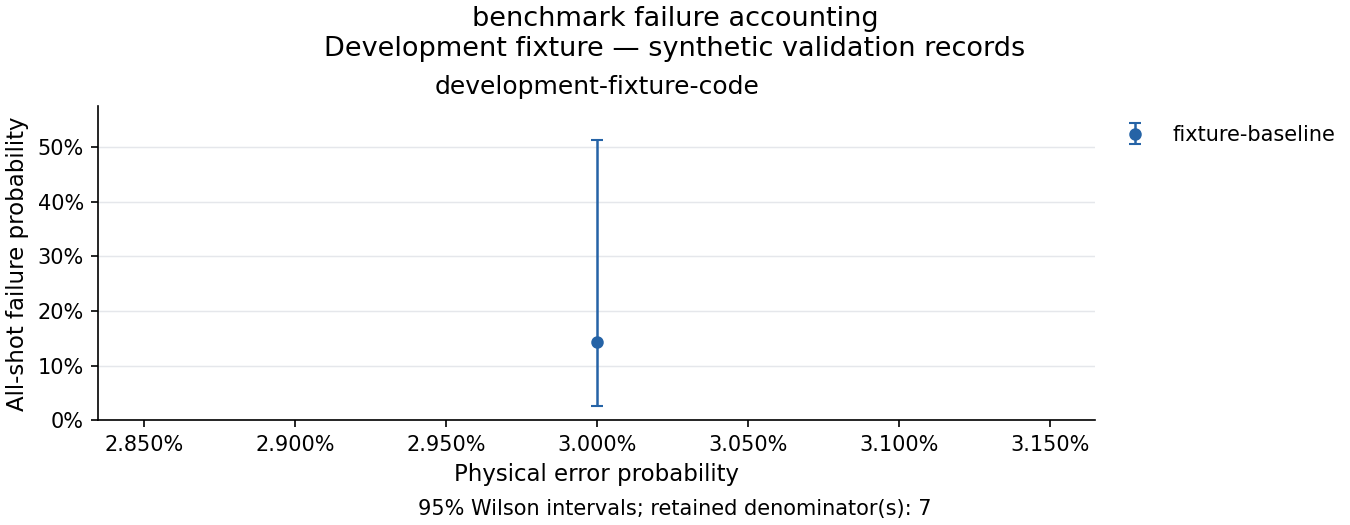

In [5]:
record = campaign.get('artifacts', {}).get('benchmark', stages['benchmark'])
view = display_campaign_stage('benchmark', record, campaign, figure_dir=figure_dir)


## 5. Complete tuning surfaces

Only terminal calibration evidence may support selection. Show every attempted coarse/refinement configuration, fixed controls, Wilson intervals, work, failure and inconclusive state. Do not read evaluation outcomes for tuning.

stage,code_id,arm,error_rate,failures,denominator,estimate,wilson_95,runtime_tails,runtime_scope,resource_tails,diagnostic_cells,selected_valid_syndrome_logical_error,termination_counts,work_vectors
calibration,development-fixture-code,fixture-baseline,0.03,1,7,0.142857,"[0.02567962434474355, 0.5131278292743189]",{'p95': 0.01},synthetic development fixture,{'missing': 1},unavailable,unavailable,unavailable,unavailable


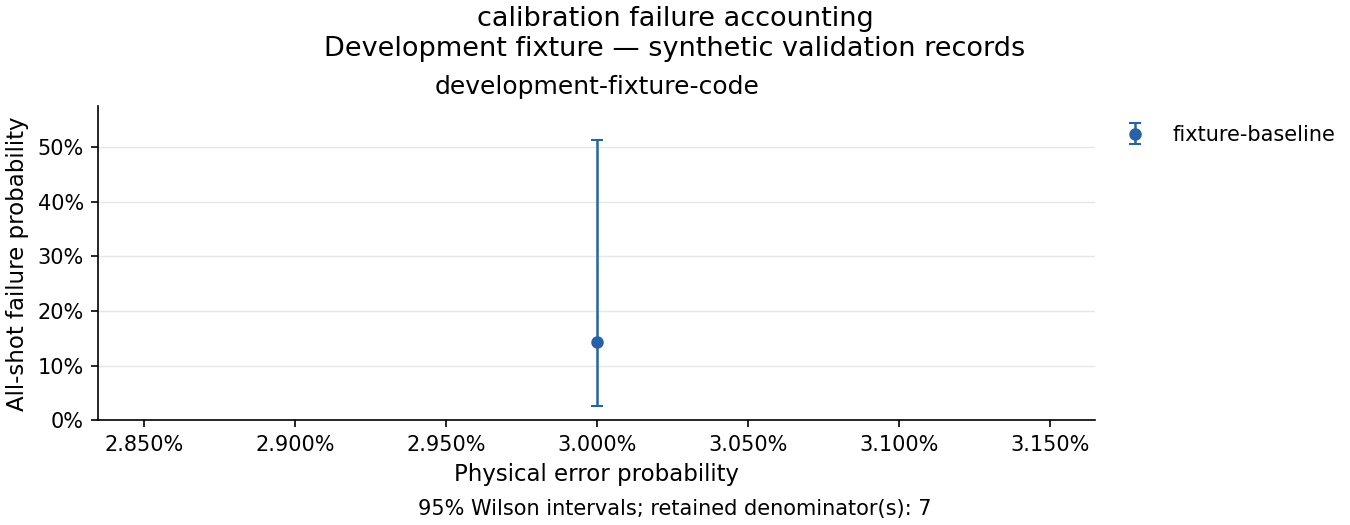

In [6]:
record = campaign.get('artifacts', {}).get('calibration', stages['calibration'])
view = display_campaign_stage('calibration', record, campaign, figure_dir=figure_dir)


## 6. Deterministic selected settings

Reconstruct selections from calibration and the frozen tie rule. Shared settings stay visible as selected candidates; the current V4 evaluation arm cap does not admit their fresh evaluation. A versioned presampling cap amendment remains required for that view.

stage,code_id,arm,error_rate,failures,denominator,estimate,wilson_95,runtime_tails,runtime_scope,resource_tails,diagnostic_cells,selected_valid_syndrome_logical_error,termination_counts,work_vectors
selected_settings,development-fixture-code,fixture-baseline,0.03,1,7,0.142857,"[0.02567962434474355, 0.5131278292743189]",{'p95': 0.01},synthetic development fixture,{'missing': 1},unavailable,unavailable,unavailable,unavailable


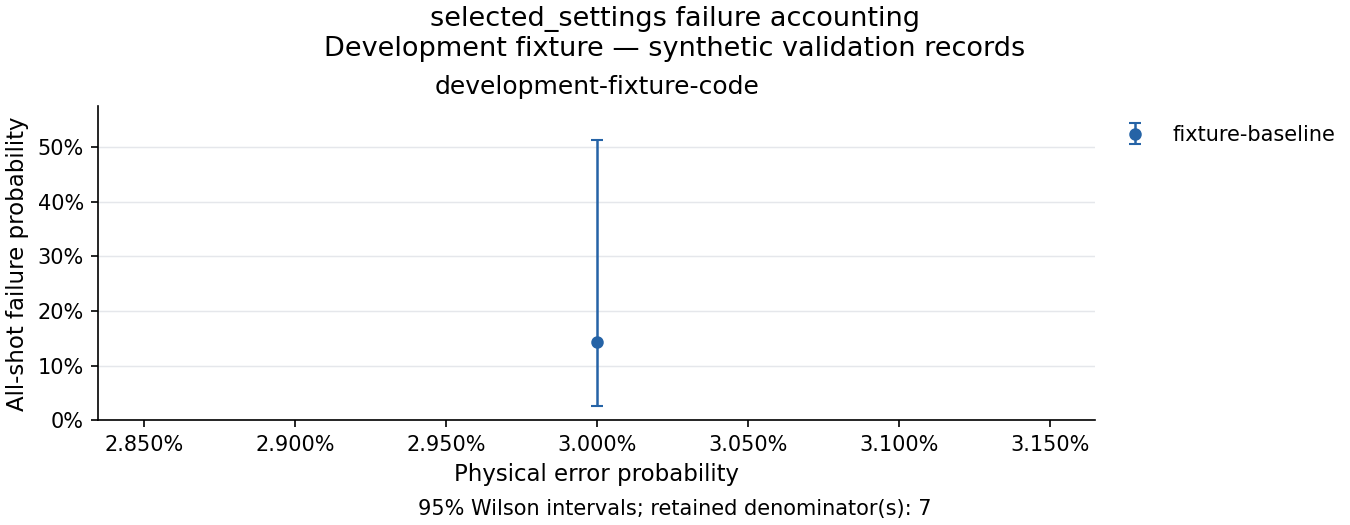

In [7]:
record = campaign.get('artifacts', {}).get('selected_settings', stages['selected_settings'])
view = display_campaign_stage('selected_settings', record, campaign, figure_dir=figure_dir)


## 7. Fresh matched evaluation

Terminal calibration and digest-verified frozen settings precede any fresh sampling. Preserve disjoint sample namespaces and unavailable/inconclusive selections. Missing evidence is unavailable, not a measured zero.

stage,code_id,arm,error_rate,failures,denominator,estimate,wilson_95,runtime_tails,runtime_scope,resource_tails,diagnostic_cells,selected_valid_syndrome_logical_error,termination_counts,work_vectors
evaluation,development-fixture-code,fixture-baseline,0.03,1,7,0.142857,"[0.02567962434474355, 0.5131278292743189]",{'p95': 0.01},synthetic development fixture,{'missing': 1},unavailable,unavailable,unavailable,unavailable


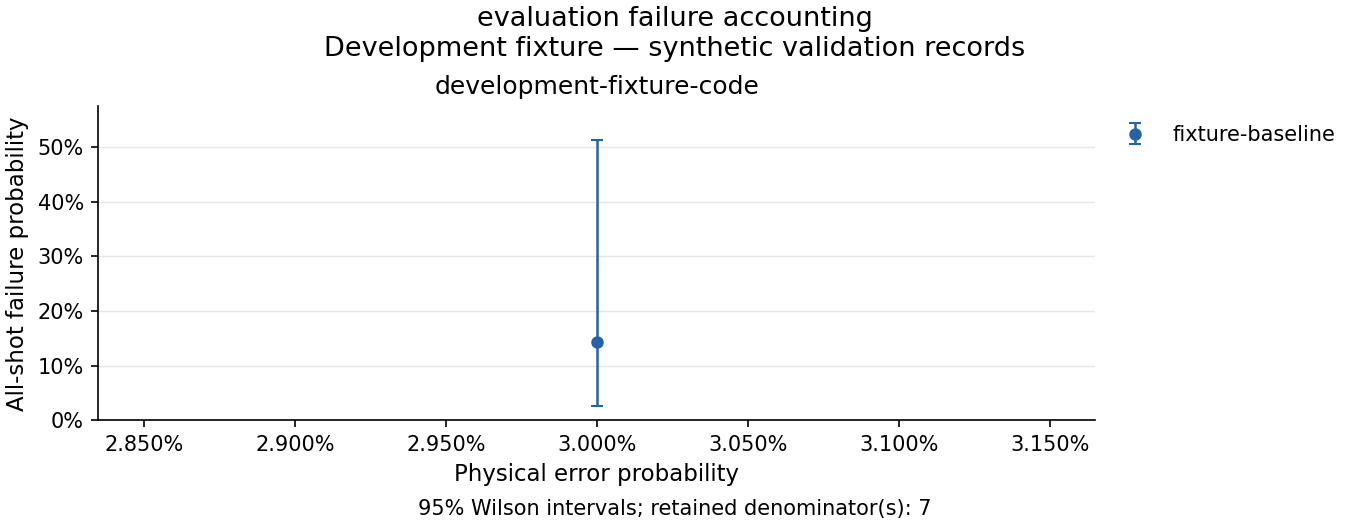

In [8]:
record = campaign.get('artifacts', {}).get('evaluation', stages['evaluation'])
view = display_campaign_stage('evaluation', record, campaign, figure_dir=figure_dir)


## 8. Focused memory and Relay ablations

The frozen design has 14 arms, three noise regions and three qualified codes. Outcome-independent coefficients and executable order are specified in the versioned supplement. Keep valid/correct, valid/wrong-logical, invalid/correct-projection, invalid/wrong-projection and no-proposal cells. No proposal counts as all-shot failure.

stage,code_id,arm,error_rate,failures,denominator,estimate,wilson_95,runtime_tails,runtime_scope,resource_tails,diagnostic_cells,selected_valid_syndrome_logical_error,termination_counts,work_vectors
factorial,development-fixture-code,fixture-baseline,0.03,1,7,0.142857,"[0.02567962434474355, 0.5131278292743189]",{'p95': 0.01},synthetic development fixture,{'missing': 1},unavailable,unavailable,unavailable,unavailable


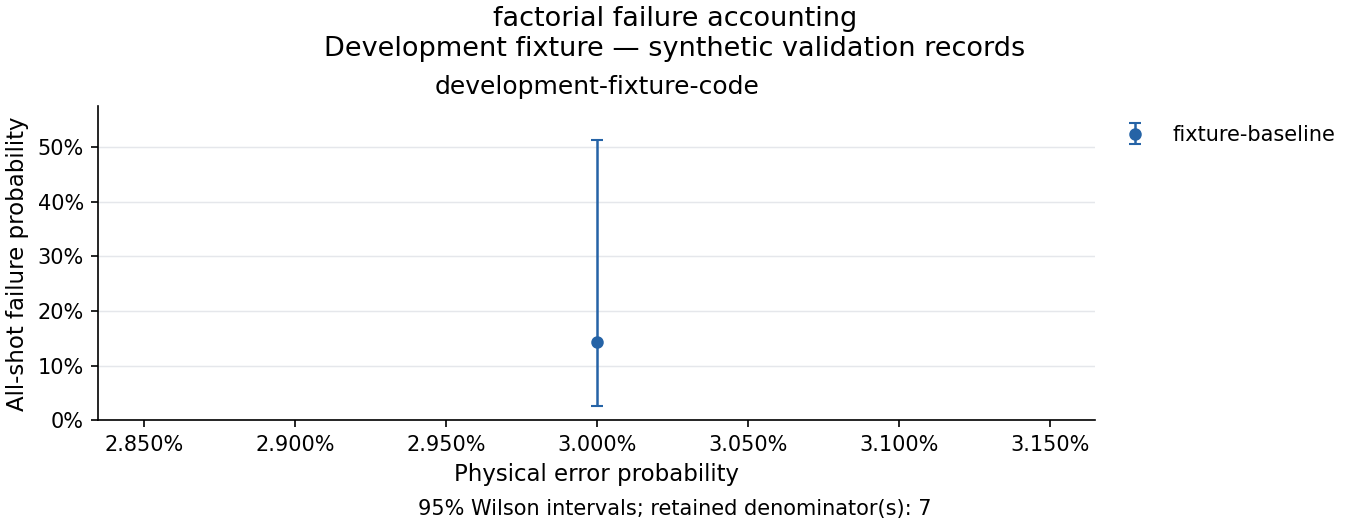

In [9]:
record = campaign.get('artifacts', {}).get('factorial', stages['factorial'])
view = display_campaign_stage('factorial', record, campaign, figure_dir=figure_dir)


## 9. Exact-author paired diagnostics

Only trmue/relay v0.2.2 at commit 14cb31a18f9b9d7d099791b793e35b8a2951f8f3 qualifies as the original reference. Retain import origin, explicit gamma assignments, paired sample identities, disagreement intervals and missing instrumentation. The completed author-agreement auxiliary campaign is separate from fresh evaluation.

stage,code_id,arm,error_rate,failures,denominator,estimate,wilson_95,runtime_tails,runtime_scope,resource_tails,diagnostic_cells,selected_valid_syndrome_logical_error,termination_counts,work_vectors
native,development-fixture-code,fixture-baseline,0.03,1,7,0.142857,"[0.02567962434474355, 0.5131278292743189]",{'p95': 0.01},synthetic development fixture,{'missing': 1},unavailable,unavailable,unavailable,unavailable


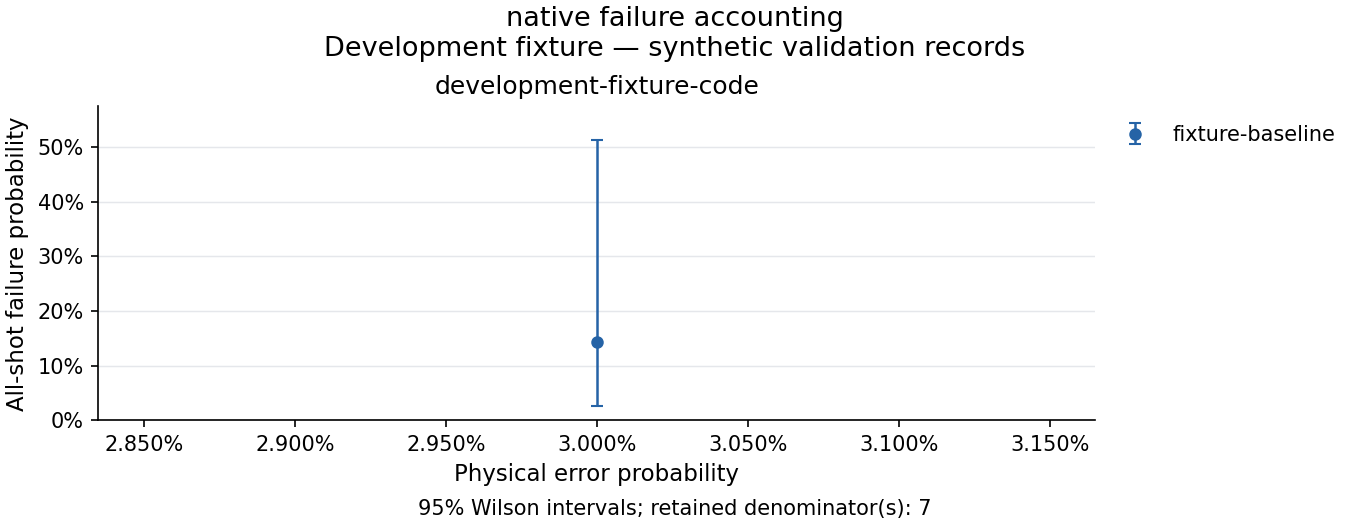

In [10]:
record = campaign.get('artifacts', {}).get('native', stages['native'])
view = display_campaign_stage('native', record, campaign, figure_dir=figure_dir)


## 10. Bounded representative traces

Link beliefs, private histories, draws, Relay leg transitions, work and candidate origins to public ledger identities. State record/byte caps and truncation explicitly. Diagnostic selection is not representative population sampling.

stage,code_id,arm,error_rate,failures,denominator,estimate,wilson_95,runtime_tails,runtime_scope,resource_tails,diagnostic_cells,selected_valid_syndrome_logical_error,termination_counts,work_vectors
traces,development-fixture-code,fixture-baseline,0.03,1,7,0.142857,"[0.02567962434474355, 0.5131278292743189]",{'p95': 0.01},synthetic development fixture,{'missing': 1},unavailable,unavailable,unavailable,unavailable


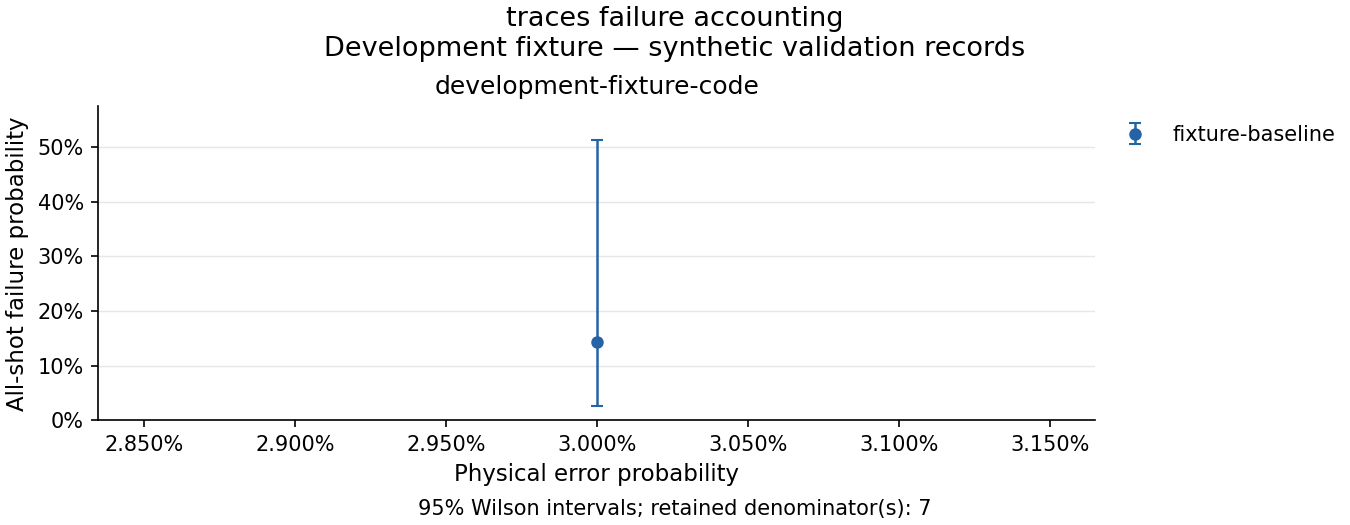

In [11]:
record = campaign.get('artifacts', {}).get('traces', stages['traces'])
view = display_campaign_stage('traces', record, campaign, figure_dir=figure_dir)


## 11. Work, runtime, resource tails and setup cost

Report raw per-leg and total work, runtime/resource quantiles including upper tails, tuning/setup costs, and measurement missingness. Never combine heterogeneous work/time/resource components into an unexplained scalar cost.

In [12]:
record = campaign.get('artifacts', {}).get('work_runtime_resources', stages['work_runtime_resources'])
view = display_campaign_stage('work_runtime_resources', record, campaign, figure_dir=figure_dir)


source_stage,code_id,arm,configuration_id,error_rate,runtime_scope,runtime_tails,public_elapsed_seconds,work_vectors,raw_work,resource_tails
benchmark,development-fixture-code,fixture-baseline,unavailable,0.03,synthetic development fixture,{'p95': 0.01},unavailable,unavailable,unavailable,{'missing': 1}


source_stage,code_id,arm,configuration_id,error_rate,runtime_scope,runtime_tails,public_elapsed_seconds,work_vectors,raw_work,resource_tails
calibration,development-fixture-code,fixture-baseline,unavailable,0.03,synthetic development fixture,{'p95': 0.01},unavailable,unavailable,unavailable,{'missing': 1}


source_stage,code_id,arm,configuration_id,error_rate,runtime_scope,runtime_tails,public_elapsed_seconds,work_vectors,raw_work,resource_tails
evaluation,development-fixture-code,fixture-baseline,unavailable,0.03,synthetic development fixture,{'p95': 0.01},unavailable,unavailable,unavailable,{'missing': 1}


source_stage,code_id,arm,configuration_id,error_rate,runtime_scope,runtime_tails,public_elapsed_seconds,work_vectors,raw_work,resource_tails
factorial,development-fixture-code,fixture-baseline,unavailable,0.03,synthetic development fixture,{'p95': 0.01},unavailable,unavailable,unavailable,{'missing': 1}


source_stage,code_id,arm,configuration_id,error_rate,runtime_scope,runtime_tails,public_elapsed_seconds,work_vectors,raw_work,resource_tails
native,development-fixture-code,fixture-baseline,unavailable,0.03,synthetic development fixture,{'p95': 0.01},unavailable,unavailable,unavailable,{'missing': 1}


## 12. Cross-code comparison

Use comparable identified controls and matched samples within each code. Preserve code/rate/arm denominators, Wilson uncertainty, paired discordances and exact paired tests. These CSS pilots do not establish a universal decoder ranking.

stage,code_id,arm,error_rate,failures,denominator,estimate,wilson_95,runtime_tails,runtime_scope,resource_tails,diagnostic_cells,selected_valid_syndrome_logical_error,termination_counts,work_vectors
evaluation,development-fixture-code,fixture-baseline,0.03,1,7,0.142857,"[0.02567962434474355, 0.5131278292743189]",{'p95': 0.01},synthetic development fixture,{'missing': 1},unavailable,unavailable,unavailable,unavailable


stage,code_id,arm,error_rate,failures,denominator,estimate,wilson_95,runtime_tails,runtime_scope,resource_tails,diagnostic_cells,selected_valid_syndrome_logical_error,termination_counts,work_vectors
factorial,development-fixture-code,fixture-baseline,0.03,1,7,0.142857,"[0.02567962434474355, 0.5131278292743189]",{'p95': 0.01},synthetic development fixture,{'missing': 1},unavailable,unavailable,unavailable,unavailable


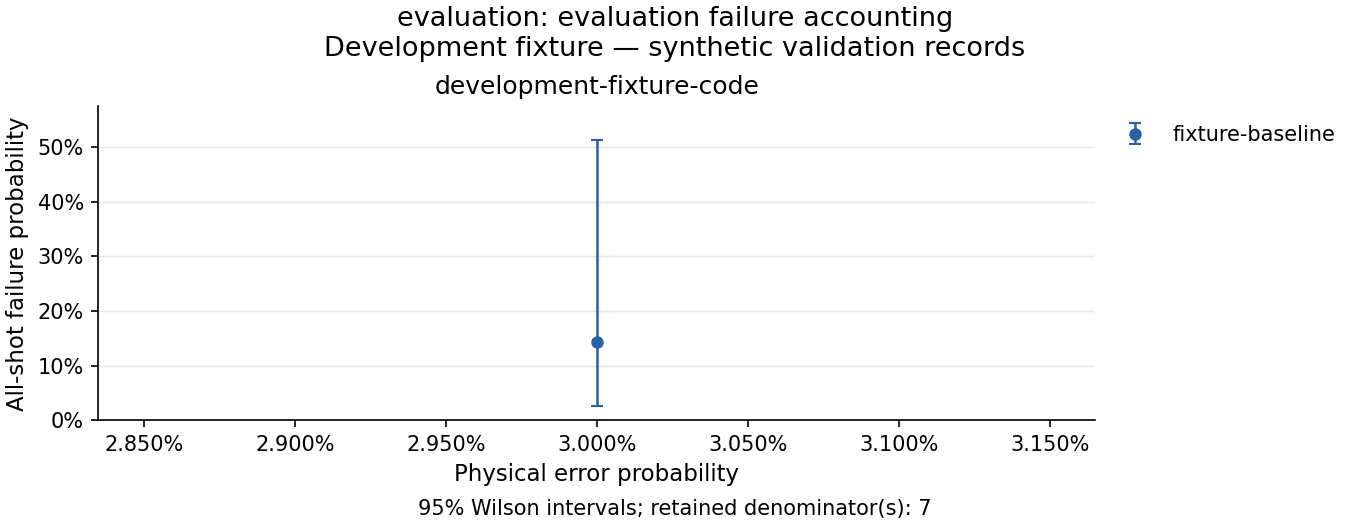

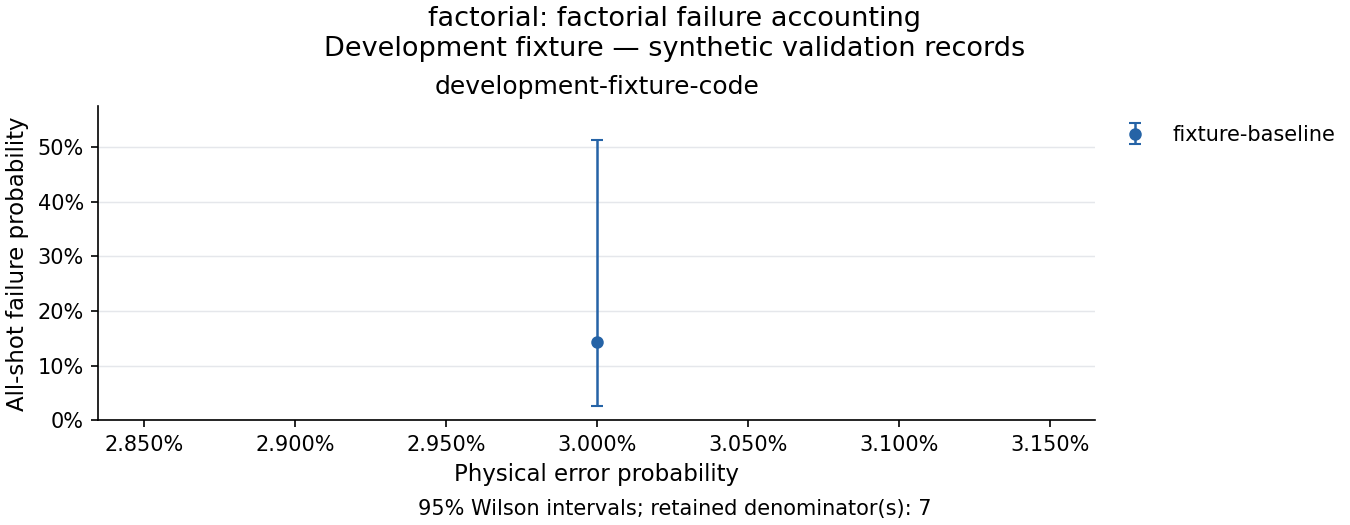

In [13]:
record = campaign.get('artifacts', {}).get('cross_code', stages['cross_code'])
view = display_campaign_stage('cross_code', record, campaign, figure_dir=figure_dir)


## 13. Limitations and remaining gates

Plan 04-12 awaits live calibration. Plans 04-13 and 04-14 await production evidence; local-schedule/history-lifetime coverage and shared-setting cap admission remain explicit gaps. Quantitative views are implemented and display qualified evidence when available. Fixture figures validate calculations and presentation with explicitly synthetic records. Quaternary/circuit execution and publication assessment belong to later phases.

In [14]:
record = campaign.get('artifacts', {}).get('limitations', stages['limitations'])
view = display_campaign_stage('limitations', record, campaign, figure_dir=figure_dir)
